# Diabetes Prediction using Machine Learning
End-to-end classification pipeline using Pandas and Scikit-learn.

## Part 1 — Data Preparation
### 1. Load the dataset

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

df = pd.read_csv("diabets.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### 2. Explore the dataset

In [ ]:
print("Shape:", df.shape)
print("\nColumns:", list(df.columns))
print("\nData types:")
print(df.dtypes)
print("\nMissing values (NaN):")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Shape: (768, 9)

Columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Data types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

Missing values (NaN):
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Duplicate rows: 0


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [ ]:
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print("Zero counts in columns where zero is physiologically impossible:")
print((df[cols] == 0).sum())
print("\nClass distribution:")
print(df["Outcome"].value_counts())
print(df["Outcome"].value_counts(normalize=True).round(3))

Zero counts in columns where zero is physiologically impossible:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Class distribution:
Outcome
0    500
1    268
Name: count, dtype: int64
Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64


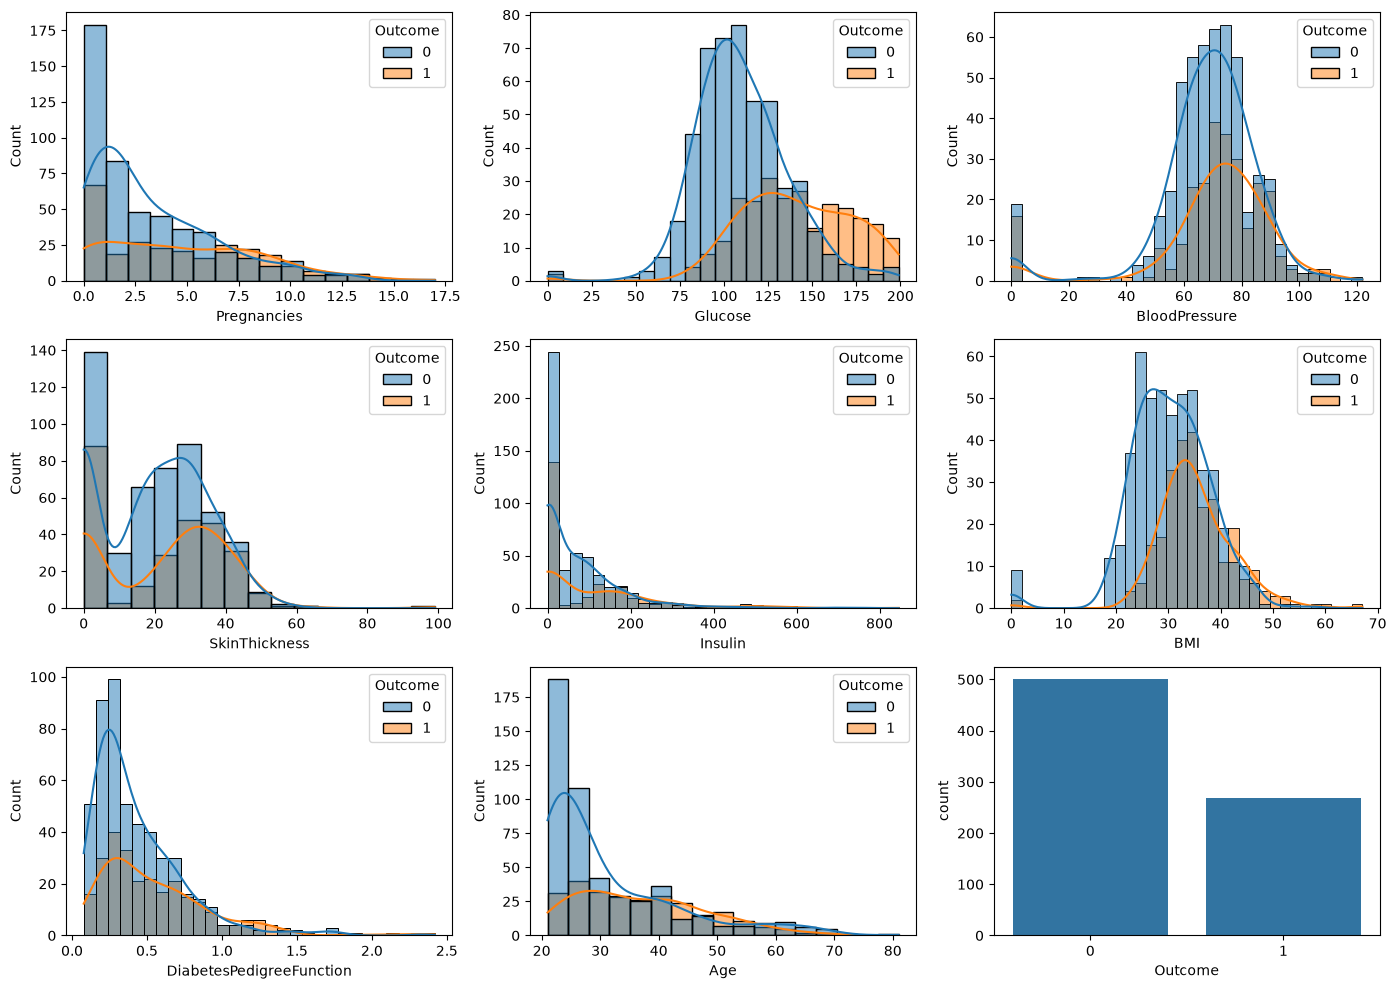

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.ravel(), df.columns[:-1]):
    sns.histplot(data=df, x=col, hue="Outcome", kde=True, ax=ax)
sns.countplot(data=df, x="Outcome", ax=axes[2, 2])
plt.tight_layout()
plt.show()

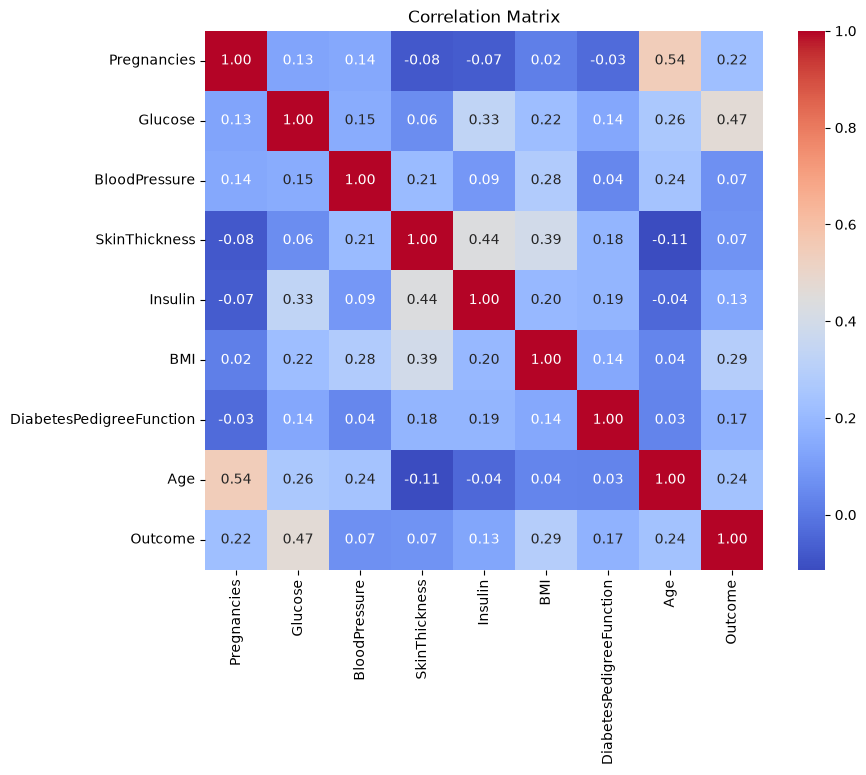

In [ ]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

**Exploration summary**
- 768 rows, 9 columns; all columns are numeric (no categorical variables).
- No `NaN` values, but `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` and `BMI` contain zeros, which are physiologically impossible and represent hidden missing values. `SkinThickness` and `Insulin` are the worst affected.
- The target is imbalanced: about 65% non-diabetic and 35% diabetic.
- `Glucose` has the strongest correlation with `Outcome`, followed by `BMI`, `Age` and `Pregnancies`.

### 3. Features and target
| Column | Role | Description |
|---|---|---|
| Pregnancies | Feature | Number of times pregnant |
| Glucose | Feature | Plasma glucose concentration |
| BloodPressure | Feature | Diastolic blood pressure |
| SkinThickness | Feature | Triceps skin fold thickness |
| Insulin | Feature | Serum insulin level |
| BMI | Feature | Body Mass Index |
| DiabetesPedigreeFunction | Feature | Diabetes pedigree score |
| Age | Feature | Age of the patient |
| Outcome | **Target** | 0 = No Diabetes, 1 = Diabetes |

In [ ]:
X = df.drop(columns="Outcome")
y = df["Outcome"]
print(X.shape, y.shape)

(768, 8) (768,)


### 4. Train-test split
An 80/20 stratified split keeps the class ratio the same in both sets. The split happens before any preprocessing is fitted, which prevents data leakage.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Training set:", X_train.shape, "| Testing set:", X_test.shape)
print("Train class ratio:", y_train.mean().round(3), "| Test class ratio:", y_test.mean().round(3))

Training set: (614, 8) | Testing set: (154, 8)
Train class ratio: 0.349 | Test class ratio: 0.351


### 5. Preprocessing
- **Missing values:** zeros in the five columns above are converted to `NaN` and imputed with the median of the training set (median is robust to the skew in `Insulin` and `SkinThickness`).
- **Categorical encoding:** not required, as all features are numeric.
- **Scaling:** features are standardised (zero mean, unit variance) using statistics from the training set only, because Logistic Regression is sensitive to feature scale.

In [ ]:
X_train = X_train.copy()
X_test = X_test.copy()
X_train[cols] = X_train[cols].replace(0, np.nan)
X_test[cols] = X_test[cols].replace(0, np.nan)

imputer = SimpleImputer(strategy="median")
X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_imp)
X_test_s = scaler.transform(X_test_imp)

print("Missing values after imputation (train):", np.isnan(X_train_imp).sum())
print("Scaled train mean (approx):", X_train_s.mean(axis=0).round(2))
print("Scaled train std:", X_train_s.std(axis=0).round(2))
print("\nTraining size:", X_train_s.shape[0], "| Testing size:", X_test_s.shape[0])

Missing values after imputation (train): 0
Scaled train mean (approx): [-0. -0.  0. -0. -0.  0. -0. -0.]
Scaled train std: [1. 1. 1. 1. 1. 1. 1. 1.]

Training size: 614 | Testing size: 154


**Part 1 deliverables:** exploration summary above; features and target described in the table; preprocessing is median imputation of hidden missing values plus standardisation; the split is **614 training / 154 testing** samples.

## Part 2 — Machine Learning Model Building
**Algorithm: Logistic Regression.**

Why it suits this problem:
- The task is binary classification (diabetes vs. no diabetes) and Logistic Regression models the probability of the positive class directly.
- The dataset is small (768 rows) with eight numeric features, so a simple model is less likely to overfit than complex ones.
- Coefficients are interpretable, which matters in a medical setting: each one shows how a feature changes the odds of diabetes.
- It is fast to train and gives probabilities, so the decision threshold can be tuned.
- It also makes a strong baseline against which other models can be compared.

In [ ]:
model = LogisticRegression(max_iter=1000, random_state=42)
model

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

## Part 3 — Model Training

In [ ]:
model.fit(X_train_s, y_train)
print("Model trained.")
print("Iterations to converge:", model.n_iter_)
print("Intercept:", model.intercept_.round(3))
coef = pd.Series(model.coef_[0], index=X.columns).sort_values(ascending=False)
print("\nCoefficients:")
print(coef.round(3))

Model trained.
Iterations to converge: [8]
Intercept: [-0.872]

Coefficients:
Glucose                     1.183
BMI                         0.689
Pregnancies                 0.377
DiabetesPedigreeFunction    0.233
Age                         0.148
SkinThickness               0.028
BloodPressure              -0.044
Insulin                    -0.066
dtype: float64


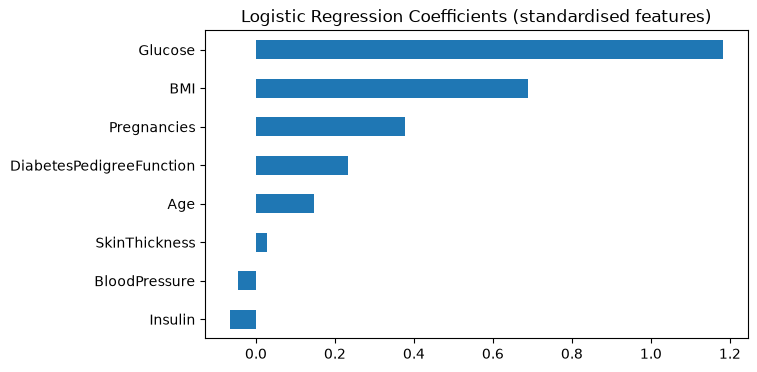

In [ ]:
coef.sort_values().plot(kind="barh", figsize=(7, 4), title="Logistic Regression Coefficients (standardised features)")
plt.show()

In [ ]:
y_train_pred = model.predict(X_train_s)
train_acc = accuracy_score(y_train, y_train_pred)
print(f"Training accuracy: {train_acc:.4f}")

Training accuracy: 0.7964


### Evaluation on the test set

In [ ]:
y_test_pred = model.predict(X_test_s)
test_acc = accuracy_score(y_test, y_test_pred)
test_prec = precision_score(y_test, y_test_pred)
test_rec = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)

print(f"Test accuracy : {test_acc:.4f}")
print(f"Precision     : {test_prec:.4f}")
print(f"Recall        : {test_rec:.4f}")
print(f"F1-score      : {test_f1:.4f}")
print()
print(classification_report(y_test, y_test_pred, target_names=["No Diabetes", "Diabetes"]))

Test accuracy : 0.7078
Precision     : 0.6000
Recall        : 0.5000
F1-score      : 0.5455



              precision    recall  f1-score   support

 No Diabetes       0.75      0.82      0.78       100
    Diabetes       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



[[82 18]
 [27 27]]


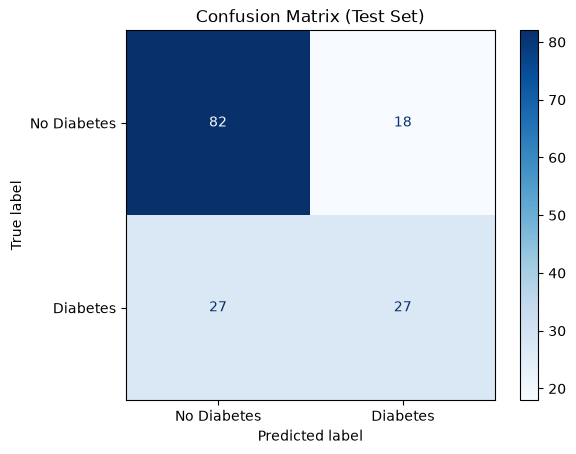

TN=82  FP=18  FN=27  TP=27


In [ ]:
cm = confusion_matrix(y_test, y_test_pred)
print(cm)
ConfusionMatrixDisplay(cm, display_labels=["No Diabetes", "Diabetes"]).plot(cmap="Blues")
plt.title("Confusion Matrix (Test Set)")
plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

In [ ]:
comparison = pd.DataFrame({
    "Accuracy": [train_acc, test_acc],
    "Precision": [precision_score(y_train, y_train_pred), test_prec],
    "Recall": [recall_score(y_train, y_train_pred), test_rec],
    "F1-score": [f1_score(y_train, y_train_pred), test_f1],
}, index=["Train", "Test"]).round(4)
comparison

,Accuracy,Precision,Recall,F1-score
Train,0.7964,0.7697,0.5935,0.6702
Test,0.7078,0.6000,0.5000,0.5455


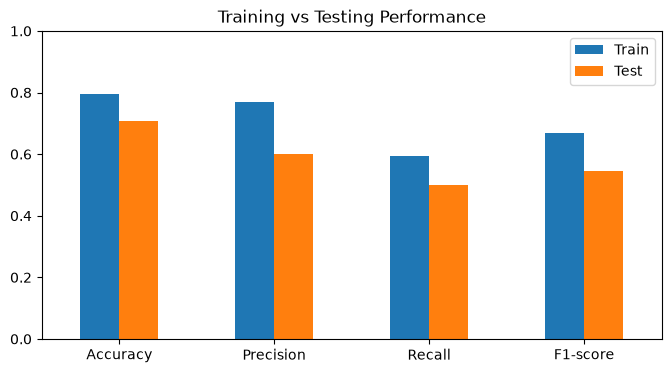

In [ ]:
comparison.T.plot(kind="bar", figsize=(8, 4), ylim=(0, 1), title="Training vs Testing Performance")
plt.xticks(rotation=0)
plt.show()

## Part 4 — Model Performance Analysis

In [ ]:
print(f"Train accuracy: {train_acc:.3f}")
print(f"Test accuracy : {test_acc:.3f}")
print(f"Gap           : {abs(train_acc - test_acc):.3f}")
print(f"Baseline (always predict majority class): {1 - y_test.mean():.3f}")

Train accuracy: 0.796
Test accuracy : 0.708
Gap           : 0.089
Baseline (always predict majority class): 0.649


### Results and interpretation

| Metric | Train | Test |
|---|---|---|
| Accuracy | 0.796 | 0.708 |

Test set (154 patients): precision 0.60, recall 0.50, F1 0.55 for the diabetic class. Confusion matrix: TN = 82, FP = 18, FN = 27, TP = 27.

**Training vs. testing:** training accuracy (79.6%) is about 9 points above test accuracy (70.8%). This shows mild overfitting, which is partly expected from a single small test split of 154 samples, where a handful of patients shifts accuracy by several points. The model is simple, so the gap is not a sign of a badly overfitted model.

**Interpretation**
- The model beats the majority-class baseline (64.9%) by only about 6 points, so it learns real signal but is only modestly useful on its own.
- It is much better at identifying non-diabetic patients (recall 0.82) than diabetic ones (recall 0.50). It misses 27 of 54 diabetic patients (false negatives), because the classes are imbalanced (65/35) and the default 0.5 threshold favours the majority class.
- Accuracy alone is misleading here; precision, recall and F1 for the diabetic class give the true picture.
- `Glucose` is the most influential feature by far, followed by `BMI`, `Pregnancies`, `DiabetesPedigreeFunction` and `Age`. This agrees with medical knowledge. `Insulin`, `SkinThickness` and `BloodPressure` contribute almost nothing, partly because many of their values were missing and had to be imputed.

**Business and analytical insights**
- In screening, a false negative (a missed diabetic patient) is costlier than a false positive, so recall for the positive class matters most. Lowering the decision threshold, or using `class_weight="balanced"`, would trade some precision for higher recall.
- Elevated glucose and BMI are the strongest risk indicators and are cheap to measure, so they are good first-line screening variables.

**Limitations and next steps**
- Use cross-validation for a more stable performance estimate than one split.
- Try tree-based models (Random Forest, Gradient Boosting) and tune hyperparameters.
- Engineer features such as age groups or BMI categories, and flag imputed values.
- Collect better data for `Insulin` and `SkinThickness`, which are missing in 49% and 30% of records respectively.

**Conclusion:** Logistic Regression gives a transparent, reasonable baseline (70.8% test accuracy), but its low recall for diabetic patients means it should be improved before it is used for screening.